In [2]:
# import libraries
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

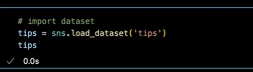

In [3]:
# import dataset
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


# SCALING

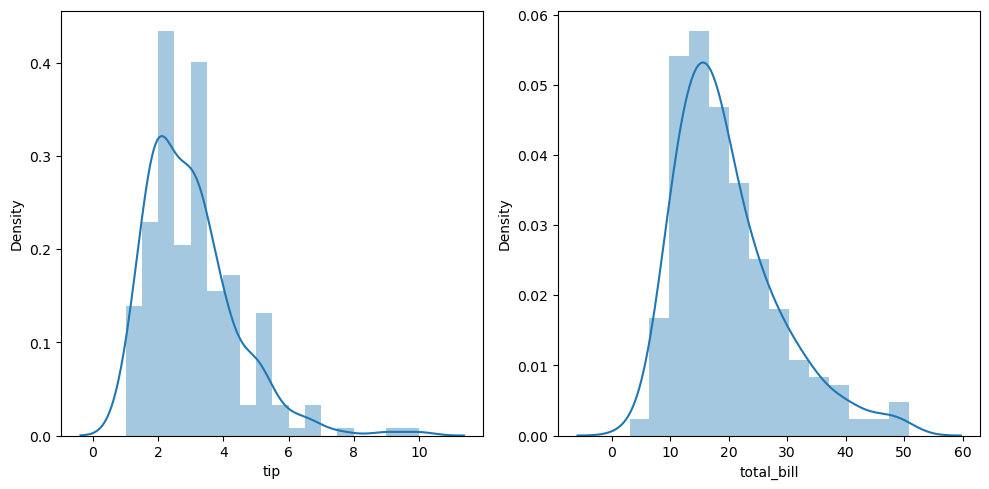

In [5]:
# some sniplet for plotting before scaling transform
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.distplot(tips['tip'])
plt.subplot(1,2,2)
sns.distplot(tips['total_bill'])
plt.tight_layout()

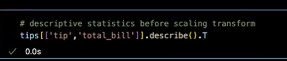

In [6]:
# descriptive statistics before scaling transform
tips[['tip','total_bill']].describe().T

,count,mean,std,min,25%,50%,75%,max
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81


In [7]:
# assign scaling preprocessing
minmax = MinMaxScaler()
standard = StandardScaler()
robust = RobustScaler()

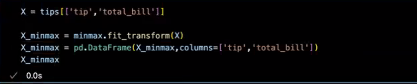

In [13]:
X = tips[['tip','total_bill']]
# normalization scaling
X_minmax = minmax.fit_transform(X)
X_minmax = pd.DataFrame(X_minmax,columns=['tip','total_bill'])
X_minmax

,tip,total_bill
0,0.001111,0.291579
1,0.073333,0.152283
2,0.277778,0.375786
3,0.256667,0.431713
4,0.290000,0.450775
...,...,...
239,0.546667,0.543779
240,0.111111,0.505027
241,0.111111,0.410557
242,0.083333,0.308965


In [14]:
# descriptive statistics before and after scaling transform
display(tips[['tip','total_bill']].describe().T,X_minmax.describe().T)

,count,mean,std,min,25%,50%,75%,max
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81


,count,mean,std,min,25%,50%,75%,max
tip,244.0,0.222031,0.153738,0.0,0.111111,0.211111,0.284722,1.0
total_bill,244.0,0.350145,0.186477,0.0,0.215281,0.308442,0.441087,1.0


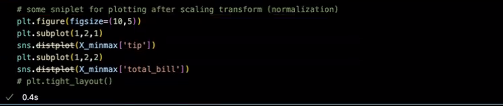

<Axes: xlabel='total_bill', ylabel='Density'>

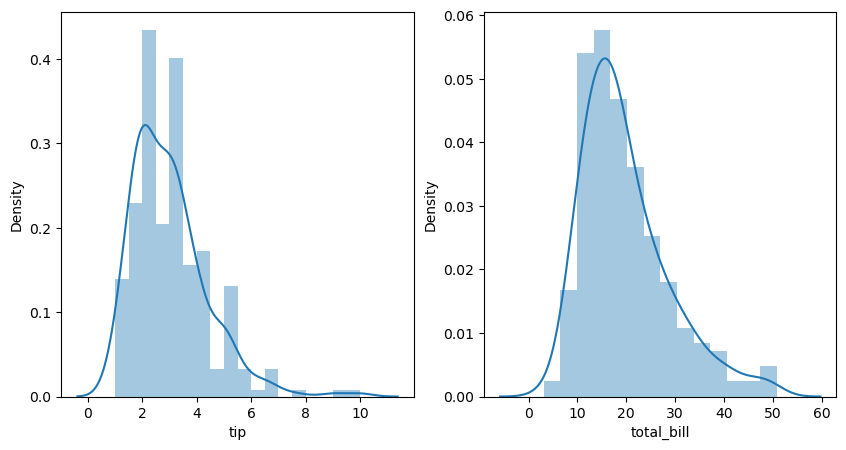

In [15]:
# some sniplet for plotting after scaling transform(normalization)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.distplot(tips['tip'])
plt.subplot(1,2,2)
sns.distplot(tips['total_bill'])
# plt.tight_layout()

In [16]:
# standard scaling
X_standard = standard.fit_transform(X)
X_standard = pd.DataFrame(X_standard,columns=['tip','total_bill'])
X_standard

,tip,total_bill
0,-1.439947,-0.314711
1,-0.969205,-1.063235
2,0.363356,0.137780
3,0.225754,0.438315
4,0.443020,0.540745
...,...,...
239,2.115963,1.040511
240,-0.722971,0.832275
241,-0.722971,0.324630
242,-0.904026,-0.221287


In [17]:
# stats desc after scaling transform(standard)
X_standard.describe().T

,count,mean,std,min,25%,50%,75%,max
tip,244.0,2.839259e-16,1.002056,-1.447189,-0.722971,-0.071175,0.408619,5.070772
total_bill,244.0,-7.871663e-17,1.002056,-1.881547,-0.724711,-0.224101,0.488686,3.492068


<Axes: xlabel='total_bill', ylabel='Density'>

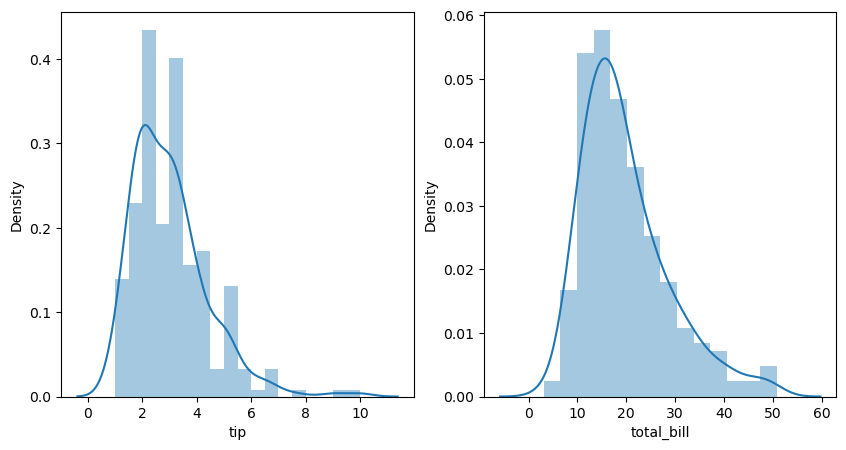

In [18]:
# some sniplet for plotting after scaling transform(standardization)
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.distplot(tips['tip'])
plt.subplot(1,2,2)
sns.distplot(tips['total_bill'])
# plt.tight_layout()

In [19]:
# robust scaling
X_robust = robust.fit_transform(X)
X_robust = pd.DataFrame(X_robust,columns=['tip','total_bill'])
X_robust

,tip,total_bill
0,-1.2096,-0.074675
1,-0.7936,-0.691558
2,0.3840,0.298237
3,0.2624,0.545918
4,0.4544,0.630334
...,...,...
239,1.9328,1.042208
240,-0.5760,0.870594
241,-0.5760,0.452226
242,-0.7360,0.002319


In [20]:
# stats desc after scaling transform (robust)
X_robust.describe().T

,count,mean,std,min,25%,50%,75%,max
tip,244.0,0.062898,0.885528,-1.216000,-0.57600,0.000000e+00,0.42400,4.544000
total_bill,244.0,0.184689,0.825827,-1.365955,-0.41257,-1.647987e-16,0.58743,3.062616


# ENCODING

In [21]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [22]:
# see all the combination value foreach categorical features
for i in ['sex','smoker','day','time']:
    print(tips[i].value_counts())


sex
Male      157
Female     87
Name: count, dtype: int64
smoker
No     151
Yes     93
Name: count, dtype: int64
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64
time
Dinner    176
Lunch      68
Name: count, dtype: int64


In [23]:
# one hot encoding
tips_dummy = pd.get_dummies(data=tips, columns=['sex','smoker','day','time'])*1
tips_dummy

,total_bill,tip,size,sex_Male,sex_Female,smoker_Yes,smoker_No,day_Thur,day_Fri,day_Sat,day_Sun,time_Lunch,time_Dinner
0,16.99,1.01,2,0,1,0,1,0,0,0,1,0,1
1,10.34,1.66,3,1,0,0,1,0,0,0,1,0,1
2,21.01,3.50,3,1,0,0,1,0,0,0,1,0,1
3,23.68,3.31,2,1,0,0,1,0,0,0,1,0,1
4,24.59,3.61,4,0,1,0,1,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,29.03,5.92,3,1,0,0,1,0,0,1,0,0,1
240,27.18,2.00,2,0,1,1,0,0,0,1,0,0,1
241,22.67,2.00,2,1,0,1,0,0,0,1,0,0,1
242,17.82,1.75,2,1,0,0,1,0,0,1,0,0,1


In [24]:
# ordinal encoding
tips_ordinal_encoding = tips.copy()

In [25]:
tips_ordinal_encoding['day'].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [26]:
tips_ordinal_encoding['day'] = tips_ordinal_encoding['day'].map(
    {
        'Thur':1,
        'Fri':2,
        'Sat':3,
        'Sun':4
    }
)
tips_ordinal_encoding

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,4,Dinner,2
1,10.34,1.66,Male,No,4,Dinner,3
2,21.01,3.50,Male,No,4,Dinner,3
3,23.68,3.31,Male,No,4,Dinner,2
4,24.59,3.61,Female,No,4,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,3,Dinner,3
240,27.18,2.00,Female,Yes,3,Dinner,2
241,22.67,2.00,Male,Yes,3,Dinner,2
242,17.82,1.75,Male,No,3,Dinner,2


In [31]:
# let's use library category_encoders
import category_encoders as ce

In [48]:
# map dict
ordinal_mapping = [
    {
        'col': 'day',
        'mapping': {
            None : 0,
            'Thur': 1,
            'Fri': 2,
            'Sat': 3,
            'Sun': 4
        }
    },
    {
        'col': 'time',
        'mapping': {
            None : 0,
            'Lunch': 1,
            'Dinner': 2
        }
    }
]

In [49]:
tips[['day','time']]

,day,time
0,Sun,Dinner
1,Sun,Dinner
2,Sun,Dinner
3,Sun,Dinner
4,Sun,Dinner
...,...,...
239,Sat,Dinner
240,Sat,Dinner
241,Sat,Dinner
242,Sat,Dinner


In [50]:
# transform
ordinal_encoders = ce.OrdinalEncoder(cols=['day','time'],mapping= ordinal_mapping)
dford = ordinal_encoders.fit_transform(tips[['day','time']])
dford

,day,time
0,4,2
1,4,2
2,4,2
3,4,2
4,4,2
...,...,...
239,3,2
240,3,2
241,3,2
242,3,2


In [51]:
# combine between tips and the ordinal encoded
tips_ordinal_encoding = pd.concat([tips[['total_bill','tip','sex','smoker','size']],dford],axis=1)
tips_ordinal_encoding

,total_bill,tip,sex,smoker,size,day,time
0,16.99,1.01,Female,No,2,4,2
1,10.34,1.66,Male,No,3,4,2
2,21.01,3.50,Male,No,3,4,2
3,23.68,3.31,Male,No,2,4,2
4,24.59,3.61,Female,No,4,4,2
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,3,3,2
240,27.18,2.00,Female,Yes,2,3,2
241,22.67,2.00,Male,Yes,2,3,2
242,17.82,1.75,Male,No,2,3,2


In [53]:
# binary encoding
binary_encoder = ce.BinaryEncoder(cols='day')
dfbin = binary_encoder.fit_transform(tips['day'])
display(tips['day'],dfbin)

0       Sun
1       Sun
2       Sun
3       Sun
4       Sun
       ... 
239     Sat
240     Sat
241     Sat
242     Sat
243    Thur
Name: day, Length: 244, dtype: category
Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']

,day_0,day_1,day_2
0,0,0,1
1,0,0,1
2,0,0,1
3,0,0,1
4,0,0,1
...,...,...,...
239,0,1,0
240,0,1,0
241,0,1,0
242,0,1,0


In [54]:
# combine between tips and the binary encoded
tips_binary_encoding = pd.concat([tips[['total_bill','tip','sex','smoker','size']],dford],axis=1)
tips_binary_encoding

,total_bill,tip,sex,smoker,size,day,time
0,16.99,1.01,Female,No,2,4,2
1,10.34,1.66,Male,No,3,4,2
2,21.01,3.50,Male,No,3,4,2
3,23.68,3.31,Male,No,2,4,2
4,24.59,3.61,Female,No,4,4,2
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,3,3,2
240,27.18,2.00,Female,Yes,2,3,2
241,22.67,2.00,Male,Yes,2,3,2
242,17.82,1.75,Male,No,2,3,2


# Applying to Modeling lifecycle
1. Data
2. Preprocessing
3. Data splitting
4. Transform
5. Model Fitting and Evaluation
6. Model Properties

In [55]:
# data
tips = sns.load_dataset('tips')

In [80]:
# preprocessing
# 1. one hot encoding : sex,smoker,time
# 2. binary encoding : day
# 3. robust scaler : total_bill
# 4. no treatment : size

transformer = ColumnTransformer(
    [
        ('OneHotEncoder', OneHotEncoder(drop='first'), ['sex', 'smoker', 'time']),
        ('BinaryEncoder', ce.BinaryEncoder(), ['day']),  # Correct usage of BinaryEncoder
        ('RobustScaler', RobustScaler(), ['total_bill'])
    ],
    remainder='passthrough'  # This will pass through other columns not listed explicitly
)

In [90]:
# Splitting
# Define the features and target variable
features = ['total_bill', 'sex', 'smoker', 'day', 'time', 'size']
target = ['tip']

# Create the feature matrix (X) and target vector (y)
X = tips[features]
y = tips[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,  # 20% of the data will be used for testing
    random_state=42  # Seed for reproducibility of results
)

In [82]:
# transform
X_train_preprocessed = transformer.fit_transform(X_train)
X_test_preprocessed = transformer.fit_transform(X_test)

In [83]:
# change to dataframe
X_train_preprocessed = pd.DataFrame(X_train_preprocessed)
X_test_preprocessed = pd.DataFrame(X_test_preprocessed)

# change the column name
list_one_hot = list(transformer.transformers_[0][1].get_feature_names_out())# output from one-hot-encoding to sex,smoker,time
list_binary = list(transformer.transformers_[1][1].get_feature_names_out())# output from binary-encoding to day
display(list_one_hot,list_binary)

['sex_Male', 'smoker_Yes', 'time_Lunch']

['day_0', 'day_1', 'day_2']

In [84]:
features = list_one_hot + list_binary + ['total_bill_scaled', 'size']
X_train_preprocessed.columns = features
X_test_preprocessed.columns = features

In [91]:
# before
tips[features]

,total_bill,sex,smoker,day,time,size
0,16.99,Female,No,Sun,Dinner,2
1,10.34,Male,No,Sun,Dinner,3
2,21.01,Male,No,Sun,Dinner,3
3,23.68,Male,No,Sun,Dinner,2
4,24.59,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...
239,29.03,Male,No,Sat,Dinner,3
240,27.18,Female,Yes,Sat,Dinner,2
241,22.67,Male,Yes,Sat,Dinner,2
242,17.82,Male,No,Sat,Dinner,2


In [ ]:
# after
display(X_train_preprocessed.head(),X_test_preprocessed.head())

,sex_Male,smoker_Yes,time_Lunch,day_0,day_1,day_2,total_bill_scaled,size
0,1.0,0.0,0.0,0.0,0.0,1.0,-0.414471,2.0
1,1.0,1.0,0.0,0.0,0.0,1.0,0.567218,2.0
2,1.0,1.0,0.0,0.0,1.0,0.0,0.836088,2.0
3,1.0,0.0,0.0,0.0,1.0,1.0,1.231800,4.0
4,1.0,0.0,1.0,1.0,0.0,0.0,-0.173292,2.0


,sex_Male,smoker_Yes,time_Lunch,day_0,day_1,day_2,total_bill_scaled,size
0,1.0,0.0,0.0,0.0,0.0,1.0,0.328727,2.0
1,1.0,0.0,0.0,0.0,1.0,0.0,-0.762093,2.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.795656,4.0
3,1.0,1.0,0.0,0.0,0.0,1.0,0.927937,4.0
4,0.0,1.0,1.0,0.0,1.0,1.0,-0.344521,2.0


In [ ]:
# model fitting and evaluation
model = Ridge()
model.fit(X_train_preprocessed,y_train)

Ridge()

In [ ]:
y_pred = model.predict(X_test_preprocessed)
print('mse',mean_squared_error(y_test,y_pred))

mse 0.8876971386306121


In [ ]:
# model properties
target_index = 0  # Index of the target for which coefficients are needed
coef_table = pd.DataFrame({
    'features': features,
    'coef': model.coef_[target_index]  # Adjust the index based on your target selection
})
coef_table

,features,coef
0,sex_Male,0.029600
1,smoker_Yes,-0.183522
2,time_Lunch,0.072316
3,day_0,-0.026031
4,day_1,0.133062
5,day_2,-0.050919
6,total_bill_scaled,1.045961
7,size,0.238771
